# Correlation: which features relate to survival?

Evidence for section B, step 1. Uses `data/titanic_800_cleaned.csv` (output of `clean.py`), so the corrupted `Fare` values are already fixed `Sex` is numeric (female = 1, male = 0) and `Embarked` is one-hot encoded (one 0/1 column per port: `Embarked_C`, `Embarked_Q`, `Embarked_S`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/titanic_800_cleaned.csv")
overall = df["Survived"].mean()
print(f"Passengers: {len(df)}, overall survival rate: {overall:.1%}")

Passengers: 800, overall survival rate: 38.5%


## 1. Correlation overview

Correlation with `Survived` for the numeric features (-1 to 1; 0 = no linear relationship). Each `Embarked_X` bar compares passengers from that port with everyone else.

Pclass       -0.325
Embarked_S   -0.135
Age          -0.087
SibSp        -0.026
Embarked_Q    0.008
Parch         0.077
Embarked_C    0.149
Fare          0.251
Sex           0.548
Name: Survived, dtype: float64


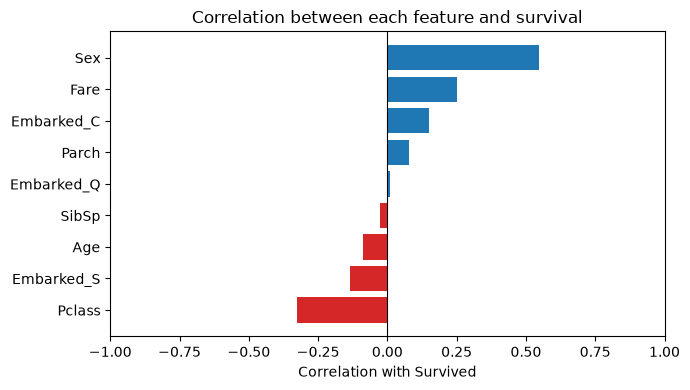

In [2]:
numeric = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked_C", "Embarked_Q", "Embarked_S"]
corr = df[numeric + ["Survived"]].corr()["Survived"].drop("Survived").sort_values()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(corr.index, corr.values, color=["tab:red" if v < 0 else "tab:blue" for v in corr.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlation with Survived")
ax.set_title("Correlation between each feature and survival")
plt.tight_layout()
plt.show()

## 2. Age: survival rate by age

`Age` has a weak correlation (close to 0), but that number only detects straight-line patterns.

- **Dots:** survival rate for each whole year of age; bigger dot = more passengers of that age.
- **Line:** a smoothed survival rate. At each age it averages survival over nearby passengers, giving the closest ages the most weight (about +/- 5 years), so single-year noise evens out. The line stops where there are too few passengers to trust it.

Missing ages are left out here.

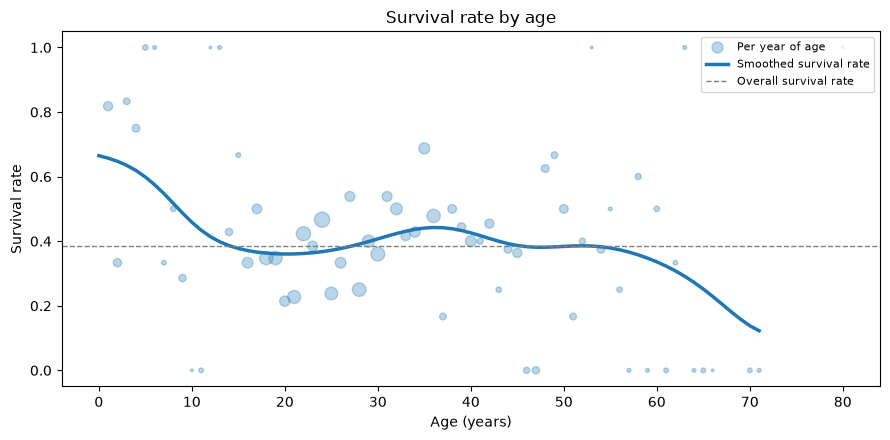

In [3]:
import numpy as np

ages = df.dropna(subset=["Age"])

# Dots: survival rate per whole year of age
per_year = ages.groupby(ages["Age"].round())["Survived"].agg(["mean", "count"])

# Line: weighted average of survival around each age (Gaussian weights, width 5 years)
grid = np.arange(0, 81)
width = 5
weights = np.exp(-0.5 * ((grid[:, None] - ages["Age"].values[None, :]) / width) ** 2)
smooth = weights @ ages["Survived"].values / weights.sum(axis=1)
# Hide the line where fewer than ~10 passengers are nearby (too little data to trust)
smooth[weights.sum(axis=1) < 10] = np.nan

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(per_year.index, per_year["mean"], s=per_year["count"] * 4, alpha=0.3, label="Per year of age")
ax.plot(grid, smooth, linewidth=2.5, label="Smoothed survival rate")
ax.axhline(overall, color="gray", linestyle="--", linewidth=1, label="Overall survival rate")
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Survival rate")
ax.set_title("Survival rate by age")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## Findings

*(To fill in after reading the plots: which features show a clear relationship with survival, and which do not.)*